# Q5 Analysis: Loyalty (Comp) Program Cost

This notebook analyzes the casino's comp program costs and trends using the `property_day` and `player_period` datasets as instructed in the Dashboard Royale datathon.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style='darkgrid')

In [2]:
# Clone the dataset repository
!git clone --depth 1 https://github.com/tamu-datathon-org/dashboard-royale.git
!cd dashboard-royale

Cloning into 'dashboard-royale'...
remote: Enumerating objects: 88, done.
remote: Counting objects: 100% (88/88), done.
remote: Compressing objects: 100% (87/87), done.
remote: Total 88 (delta 1), reused 84 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (88/88), 243.79 MiB | 28.84 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (76/76), done.


## 1. Load the Data
Assuming you have cloned the datathon repository and extracted the data files. Adjust the paths if your notebook is located in a different directory relative to the data.

In [3]:
# Load datasets (adjust paths if necessary)
try:
    property_day = pd.read_parquet('dashboard-royale/data/1_prepared_views/property_day.parquet')
    player_period = pd.read_parquet('dashboard-royale/data/1_prepared_views/player_period.parquet')
    print('Data loaded successfully!')
except Exception as e:
    print(f'Error loading data: {e}')
    print('Please ensure the data is in the correct directory (e.g. data/1_prepared_views/...).')

Data loaded successfully!


## 2. High-Level Cost Analysis (`property_day`)
Let's evaluate the total comp cost and how it changed day-to-day over the 6-month period.

In [4]:
# Total comp cost over 6 months
if 'property_day' in locals():
    total_comp_cost = property_day['comp_cost_usd'].sum()
    total_house_win = property_day['house_win_usd'].sum()
    total_theo = property_day['theo_usd'].sum()

    print(f'Total Comp Cost (Jan-Jun 2025): ${total_comp_cost:,.2f}')
    print(f'Comp as % of Expected Win (Theo): {(total_comp_cost / total_theo)*100:.2f}%')
    print(f'Comp as % of Actual House Win: {(total_comp_cost / total_house_win)*100:.2f}%')

Total Comp Cost (Jan-Jun 2025): $190,669.30
Comp as % of Expected Win (Theo): 0.81%
Comp as % of Actual House Win: 0.81%


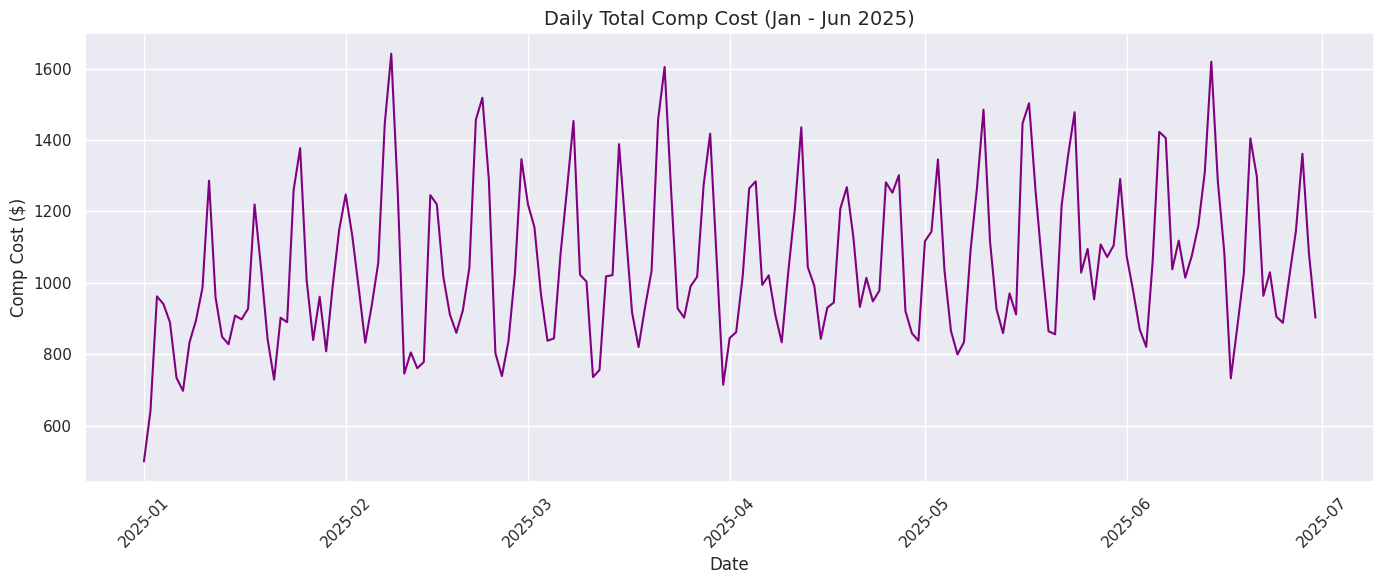

In [5]:
# Plotting daily comp costs over time
if 'property_day' in locals():
    plt.figure(figsize=(14, 6))
    sns.lineplot(data=property_day, x='gaming_date', y='comp_cost_usd', color='purple')
    plt.title('Daily Total Comp Cost (Jan - Jun 2025)', fontsize=14)
    plt.xlabel('Date')
    plt.ylabel('Comp Cost ($)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

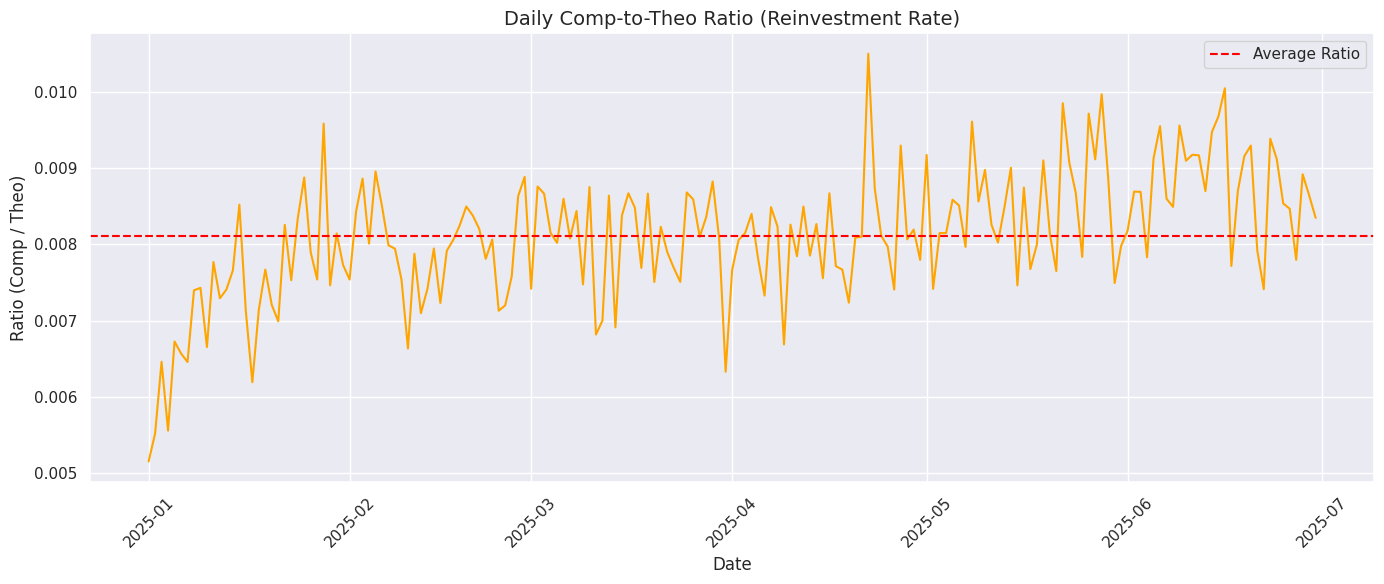

In [6]:
# Calculate and plot daily comp ratio (Comp Cost / Expected Win)
# This helps normalize the comp spending against the amount of play.
if 'property_day' in locals():
    property_day['comp_to_theo_ratio'] = property_day['comp_cost_usd'] / property_day['theo_usd']

    plt.figure(figsize=(14, 6))
    sns.lineplot(data=property_day, x='gaming_date', y='comp_to_theo_ratio', color='orange')
    plt.title('Daily Comp-to-Theo Ratio (Reinvestment Rate)', fontsize=14)
    plt.xlabel('Date')
    plt.ylabel('Ratio (Comp / Theo)')
    plt.axhline(property_day['comp_to_theo_ratio'].mean(), color='red', linestyle='--', label='Average Ratio')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 3. Player-Level Distribution (`player_period`)
Now we analyze how these comps are distributed among players by their tier and over time. Note that `player_period` is aggregated by month.

In [8]:
# Comp Cost by Tier
if 'player_period' in locals():
    tier_comps = player_period.groupby('opening_tier').agg(
        total_comp_cost=('comp_cost_usd', 'sum'),
        avg_comp_per_player=('comp_cost_usd', 'mean'),
        player_count=('player_id', 'nunique')
    ).reset_index()

    print('Comp Distribution by Tier:')
    display(tier_comps)

Comp Distribution by Tier:


,opening_tier,total_comp_cost,avg_comp_per_player,player_count
0,Base,153906.80,1.115178,111837
1,Gold,34461.80,3.422564,1900
2,Platinum,2300.70,2.829889,153


/tmp/ipykernel_820/1566767784.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tier_comps, x='opening_tier', y='total_comp_cost', palette='viridis')


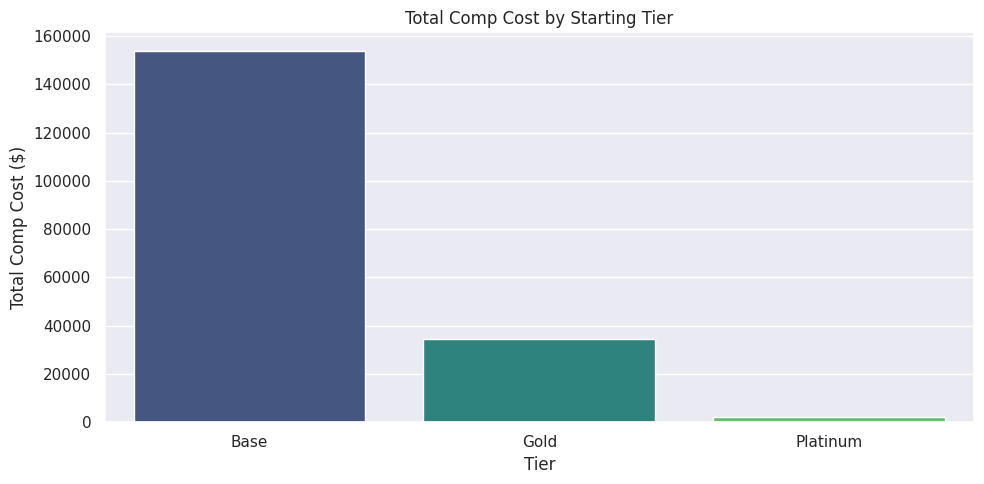

In [9]:
# Plot Comp Cost by Tier
if 'player_period' in locals():
    plt.figure(figsize=(10, 5))
    sns.barplot(data=tier_comps, x='opening_tier', y='total_comp_cost', palette='viridis')
    plt.title('Total Comp Cost by Starting Tier')
    plt.xlabel('Tier')
    plt.ylabel('Total Comp Cost ($)')
    plt.tight_layout()
    plt.show()

Monthly Trends in Player Comps:


,period_month,total_comp_cost,avg_comp_per_player,avg_theo_loss
0,2025-01,28750.30,1.164593,104.53197
1,2025-02,29854.30,1.242324,103.224993
2,2025-03,33255.50,1.26226,103.747168
3,2025-04,31390.30,1.278367,102.959705
4,2025-05,34446.10,1.32638,102.365374
5,2025-06,32972.80,1.414899,107.44564


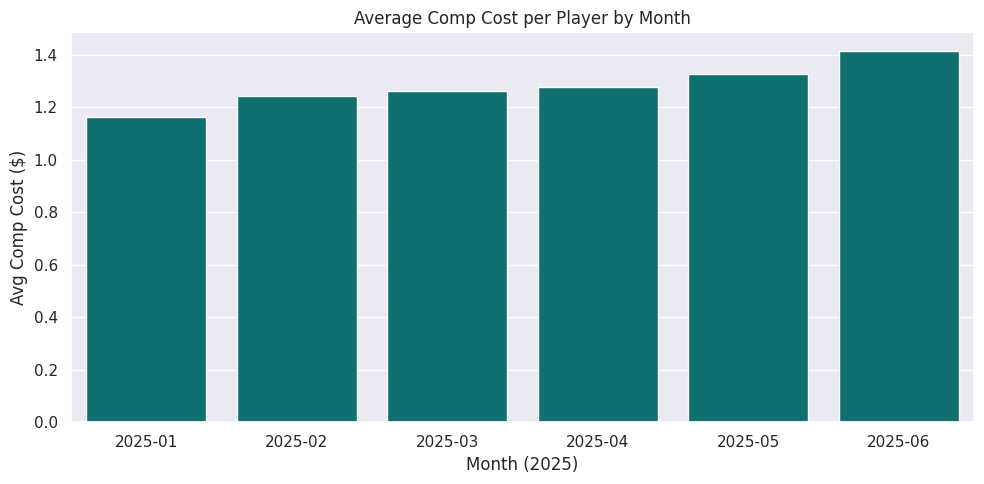

In [13]:
# Monthly shifts in Player Comps
if 'player_period' in locals():
    monthly_comps = player_period.groupby('period_month').agg(
        total_comp_cost=('comp_cost_usd', 'sum'),
        avg_comp_per_player=('comp_cost_usd', 'mean'),
        avg_theo_loss=('theo_usd', 'mean')
    ).reset_index()

    print('Monthly Trends in Player Comps:')
    display(monthly_comps)

    # Plotting
    plt.figure(figsize=(10, 5))
    sns.barplot(data=monthly_comps, x='period_month', y='avg_comp_per_player', color='teal')
    plt.title('Average Comp Cost per Player by Month')
    plt.xlabel('Month (2025)')
    plt.ylabel('Avg Comp Cost ($)')
    plt.tight_layout()
    plt.show()

## 4. ROI & Reinvestment Rate
Are the highest comp users actually generating positive net revenue for the casino? We calculate the reinvestment rate (Comps / Expected Loss).

In [14]:
if 'player_period' in locals():
    # Filter to active players who either generated theo loss or received comps
    active_players = player_period[(player_period['theo_usd'] > 0) | (player_period['comp_cost_usd'] > 0)].copy()

    # Overall reinvestment rate by tier
    reinvestment_by_tier = active_players.groupby('opening_tier').agg(
        total_comps=('comp_cost_usd', 'sum'),
        total_theo=('theo_usd', 'sum')
    )
    reinvestment_by_tier['reinvestment_rate'] = reinvestment_by_tier['total_comps'] / reinvestment_by_tier['total_theo']

    print('Reinvestment Rate by Tier (Comps / Expected Player Loss):')
    display(reinvestment_by_tier.sort_values('reinvestment_rate', ascending=False))

Reinvestment Rate by Tier (Comps / Expected Player Loss):


,total_comps,total_theo,reinvestment_rate
opening_tier,,,
Gold,34461.80,2224056.1180,0.01549502268449505013793901040
Platinum,2300.70,166984.3365,0.01377793898651086953895223580
Base,153906.80,13093980.5260,0.01175401167692251385283601421


In [15]:
if 'player_period' in locals():
    print(list(player_period.columns))

['player_id', 'period_month', 'home_region', 'age_band', 'opening_tier', 'tier_end', 'observed_visits', 'incomplete_visits', 'sessions', 'carded_play_hours', 'tracked_coin_in_usd', 'tracked_payout_usd', 'tracked_net_usd', 'theo_usd', 'luck_residual_usd', 'linked_pos_cash_usd', 'linked_pos_cogs_usd', 'comps_redeemed', 'comp_face_value_usd', 'comp_cost_usd', 'points_earned', 'points_redeemed', 'tracked_contribution_usd']
